# Bank Marketing Prediction

We are going to predict whether customers deposit after a bank marketing campaign. To acheive this, we are going to follow the steps below iteratively:

1. Cleaning
2. Exploratory Data Analysis
3. Preprocessing
4. Feature Engineering
5. Modelling
6. Evaluation

In [121]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns   

import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer, SimpleImputer
from imblearn.over_sampling import SMOTE




## Data Cleaning 

Next we want to clean the data, we are checking:
1. Missing Values
2. Adjust Data Types
3. Remove Duplicates
4. Data Formating and Standardization
5. Handle outliers 

In [122]:
# import dataset
bank_marketing = pd.read_csv('/Users/doluwamusolana/Documents/UTIVA/bank_marketing.csv')
bank_marketing.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [123]:
bank_marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [124]:
bank_marketing.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [125]:
#Collect Categorical Columns
bank_marketing.select_dtypes(include=['object']).columns
categorical_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y']

In [126]:
# Check unique values for each categorical column
for col in categorical_cols:
    print(bank_marketing[col].unique())

['management' 'technician' 'entrepreneur' 'blue-collar' nan 'retired'
 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid' 'student']
['married' 'single' 'divorced']
['tertiary' 'secondary' nan 'primary']
['no' 'yes']
['yes' 'no']
['no' 'yes']
[nan 'cellular' 'telephone']
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']
[nan 'failure' 'other' 'success']
['no' 'yes']


### Inspect and Handle Missing Values

1. Nature of Missingness - MAR, MCAR, MNAR
2. Handling Technigues include
    - Deletion
    - Simple Impution
    - Advanced Imputation 

In [127]:
bank_marketing[bank_marketing.job.isna()].isna().sum()

age              0
job            288
marital          0
education      127
default          0
balance          0
housing          0
loan             0
contact        111
day_of_week      0
month            0
duration         0
campaign         0
pdays            0
previous         0
poutcome       255
y                0
dtype: int64

In [128]:
bank_marketing[bank_marketing.contact.isna()].isna().sum()

age                0
job              111
marital            0
education        677
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       12950
y                  0
dtype: int64

In [129]:
bank_marketing[bank_marketing.education.isna()].isna().sum()

age               0
job             127
marital           0
education      1857
default           0
balance           0
housing           0
loan              0
contact         677
day_of_week       0
month             0
duration          0
campaign          0
pdays             0
previous          0
poutcome       1534
y                 0
dtype: int64

In [130]:
bank_marketing[bank_marketing.poutcome.isna()].isna().sum()

age                0
job              255
marital            0
education       1534
default            0
balance            0
housing            0
loan               0
contact        12950
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64

In [131]:
# Fill missing values in poutcome column with 'nonexistent'
bank_marketing['poutcome'] = bank_marketing['poutcome'].fillna('nonexistent')

#fill missing values in job with another category 'unknown'
bank_marketing['job'] = bank_marketing['job'].fillna('other')

#fill missing values in contact with another category 'unknown'
bank_marketing['contact'] = bank_marketing['contact'].fillna('unknown')

#fill missing values in education with another category 'unknown'
bank_marketing['education'] = bank_marketing['education'].fillna('unknown')

In [132]:
#bank_marketing.poutcome = np.where(bank_marketing.poutcome == 'other', 'nonexistent', bank_marketing.poutcome)

In [133]:
bank_marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          45211 non-null  object
 2   marital      45211 non-null  object
 3   education    45211 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      45211 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     45211 non-null  object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [134]:
#Check for Duplicates
bank_marketing.duplicated().sum()

np.int64(0)

**We have no duplicates**

#### Inspect for Outliers

In [135]:
bank_marketing.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


**The previous, pdays, campaign, duration columns seem to have outliers**

Let us investigate futher

<Axes: xlabel='previous', ylabel='Count'>

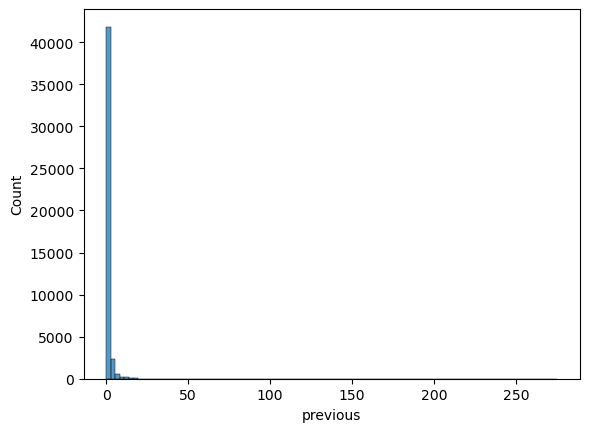

In [136]:
#
sns.histplot(bank_marketing['previous'], bins=100)

<Axes: ylabel='previous'>

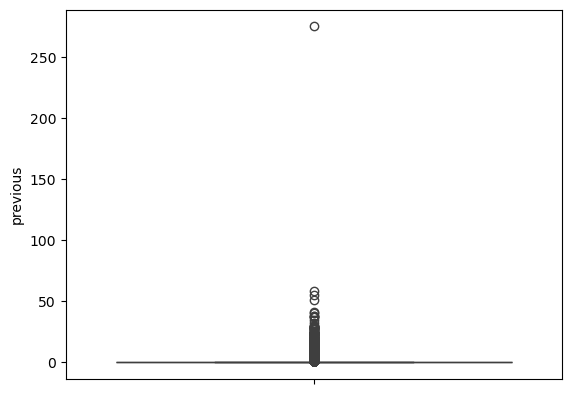

In [137]:
sns.boxplot(y='previous', data=bank_marketing)

***We would filter data above 50 because there are very rare compared to the size of the dataset**

In [187]:

bank_marketing = bank_marketing[bank_marketing.previous < 20]

<Axes: ylabel='previous'>

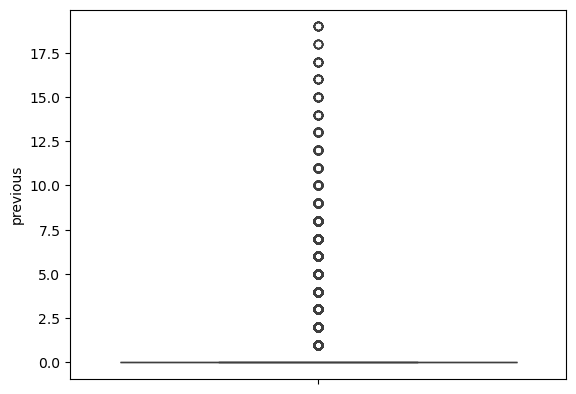

In [189]:
sns.boxplot(y='previous', data=bank_marketing)

In [140]:
bank_marketing[bank_marketing.previous > 30]

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y


**We would leave the previous column how it is and deal with other columns**


<Axes: ylabel='pdays'>

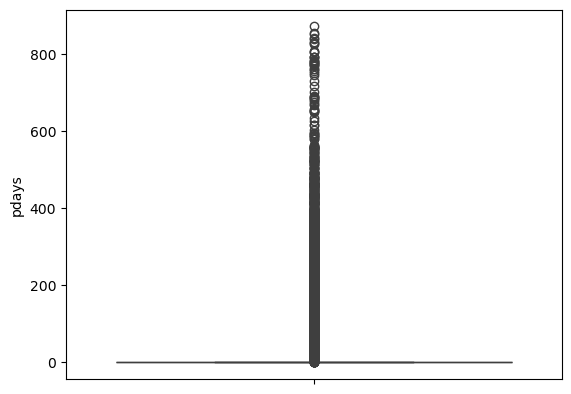

In [141]:
sns.boxplot(y='pdays', data=bank_marketing)

In [142]:
bank_marketing = bank_marketing[bank_marketing.pdays < 700]

<Axes: xlabel='pdays', ylabel='Count'>

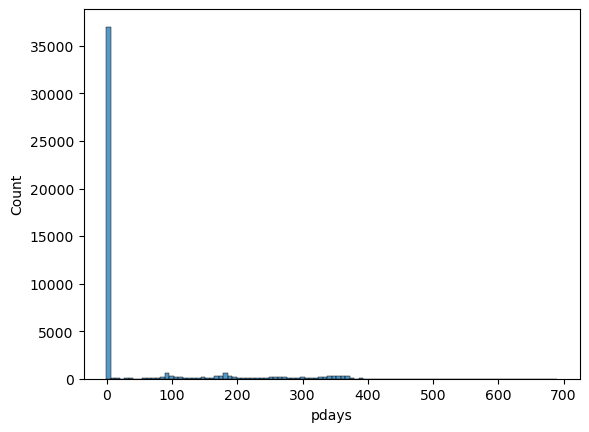

In [143]:
sns.histplot(bank_marketing['pdays'], bins=100)

<Axes: ylabel='campaign'>

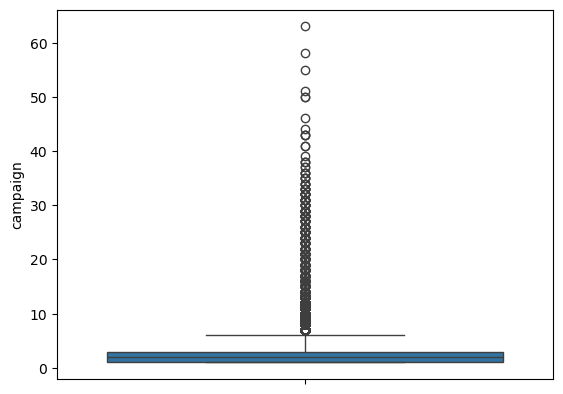

In [144]:
#checking for outliers in campaign column
sns.boxplot(y='campaign', data=bank_marketing)

In [145]:
bank_marketing = bank_marketing[bank_marketing.campaign < 40]

<Axes: ylabel='duration'>

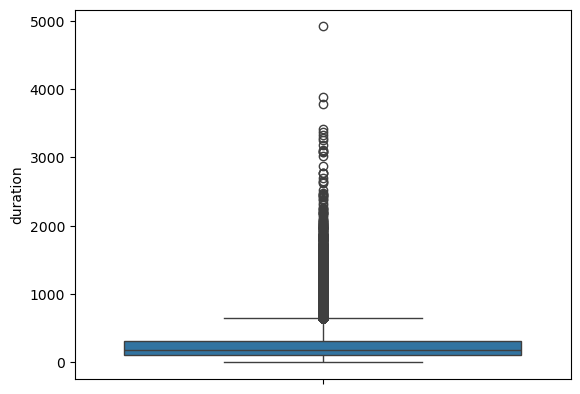

In [146]:
sns.boxplot(y='duration', data=bank_marketing)

In [147]:
bank_marketing = bank_marketing[bank_marketing.duration < 2000]

**Duration above 2500 seem excessive we can remove them from the dataset**

<Axes: ylabel='age'>

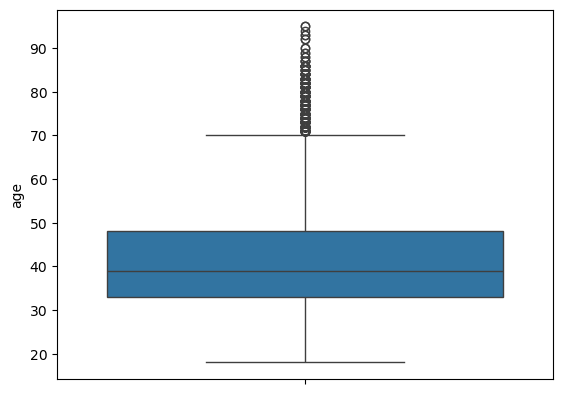

In [148]:
#Check for outliers in age column
sns.boxplot(y='age', data=bank_marketing)

<Axes: xlabel='age', ylabel='Count'>

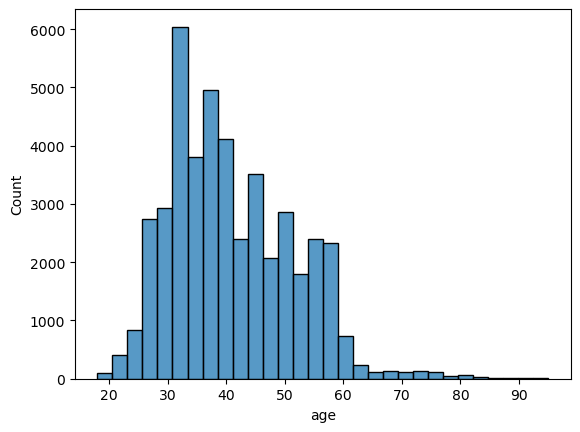

In [149]:
sns.histplot(bank_marketing['age'], bins=30)

**Though there is a handful of older people that is expected in real life**

<Axes: xlabel='balance', ylabel='Count'>

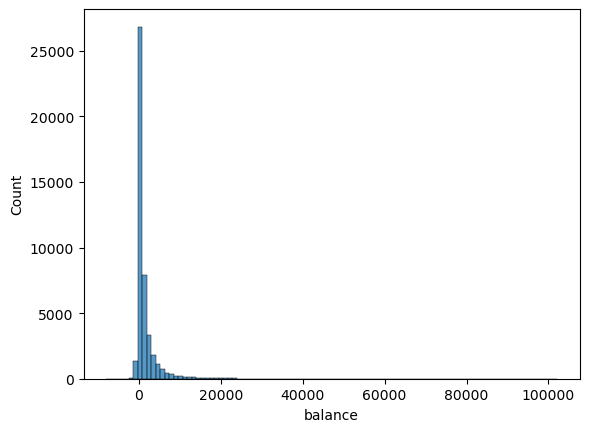

In [150]:
sns.histplot(bank_marketing['balance'], bins=100)

**There is a skew in the balance column, this is usually expected**

### Exploratory Data Analysis

Here, I am going to explore the data to understand our data and find patterns to help the model learn better by reducing multicollinearity and finding possibilities for feature engineering and selection. 

we would follow this steps:

1. Compare all the distributions in the dataset
2. Univariate analysis of Categorical Variables with barplots
3. Bivariate analysis comparing numeric cols to the target
4. Correlation Plot

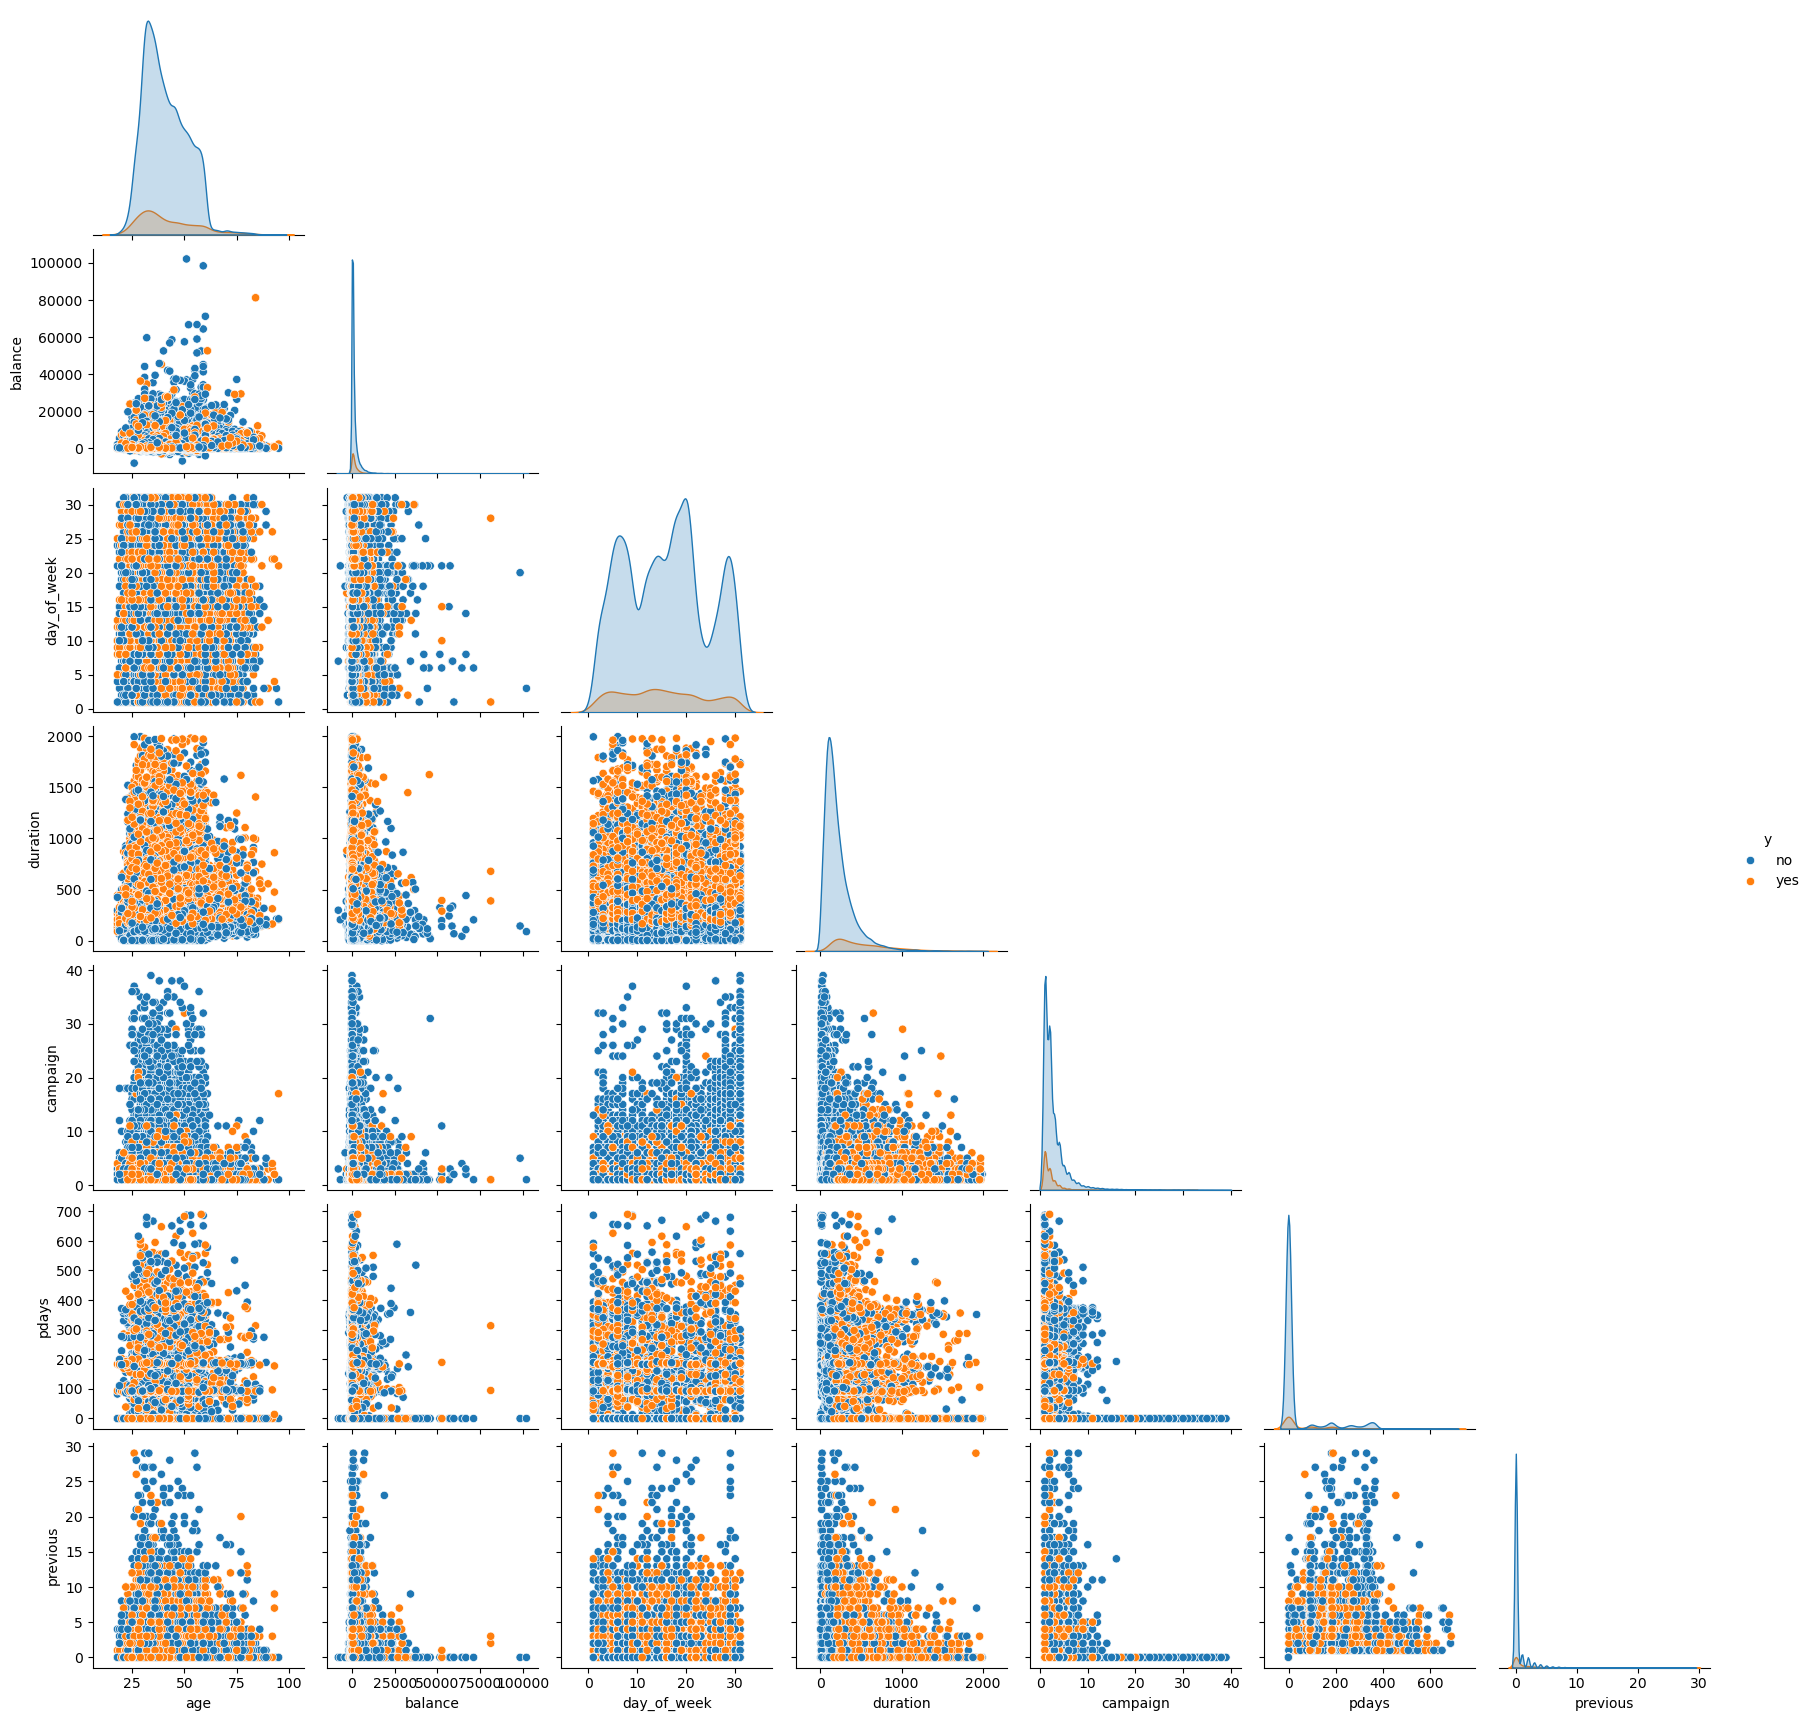

In [151]:
#pair plot
sns.pairplot(bank_marketing, hue='y',corner =True )

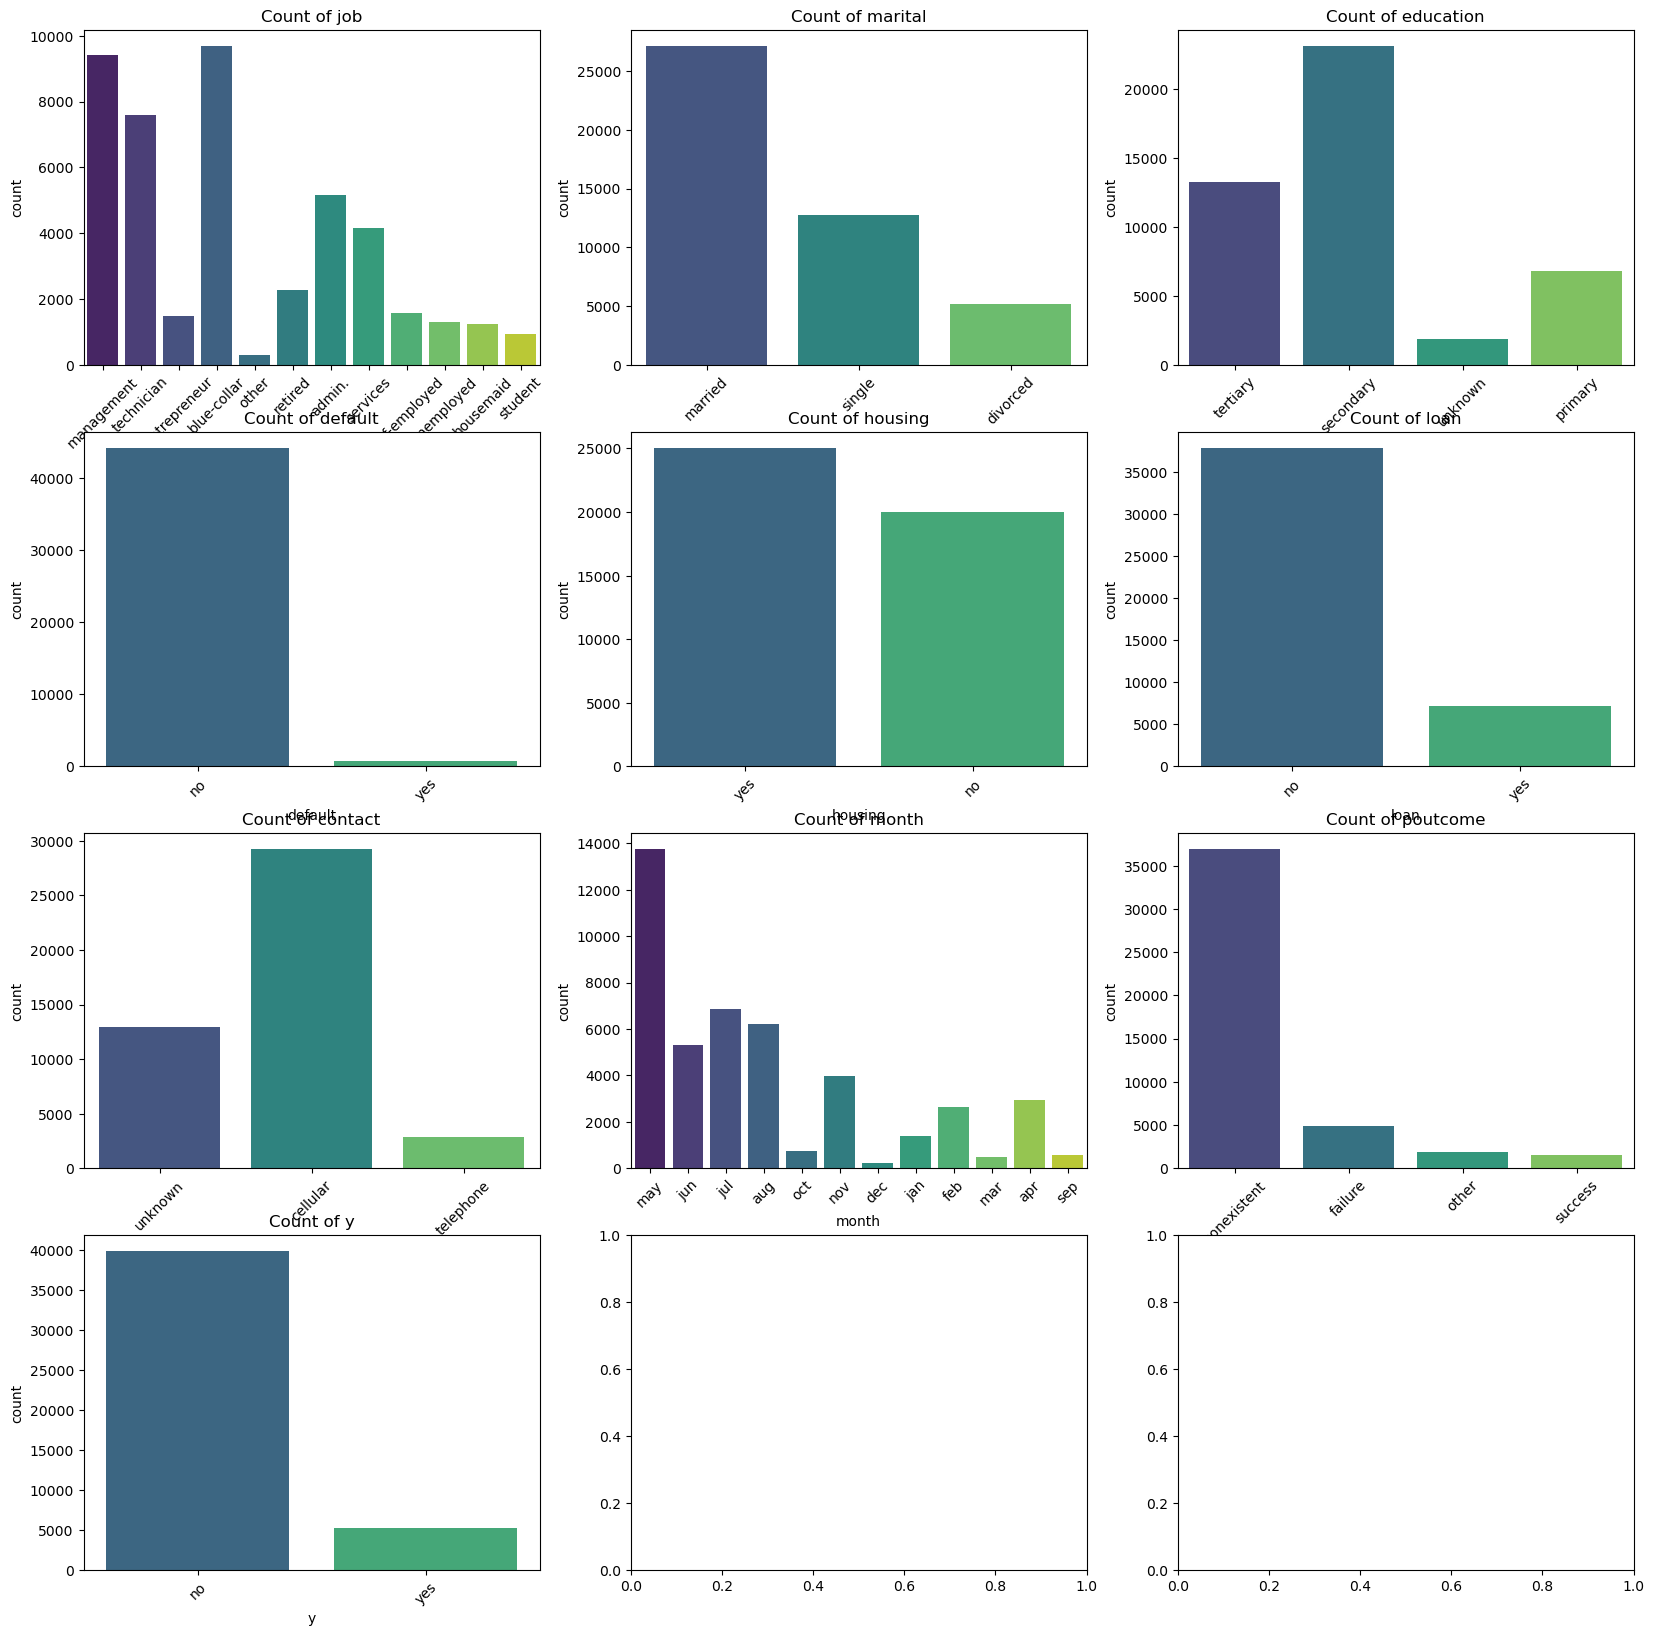

In [152]:
#subplot of categorical columns
fig, axes = plt.subplots(ncols = 3, nrows=4, figsize=(20, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(x=col, data=bank_marketing, ax=axes[i], palette="viridis")
    axes[i].set_title(f'Count of {col}')
    axes[i].tick_params(axis='x', rotation=45)

##### Observations
1. There is a class imbalance in the target variable.
2. Most people in the datasets are Married
3. Most users use Cellular

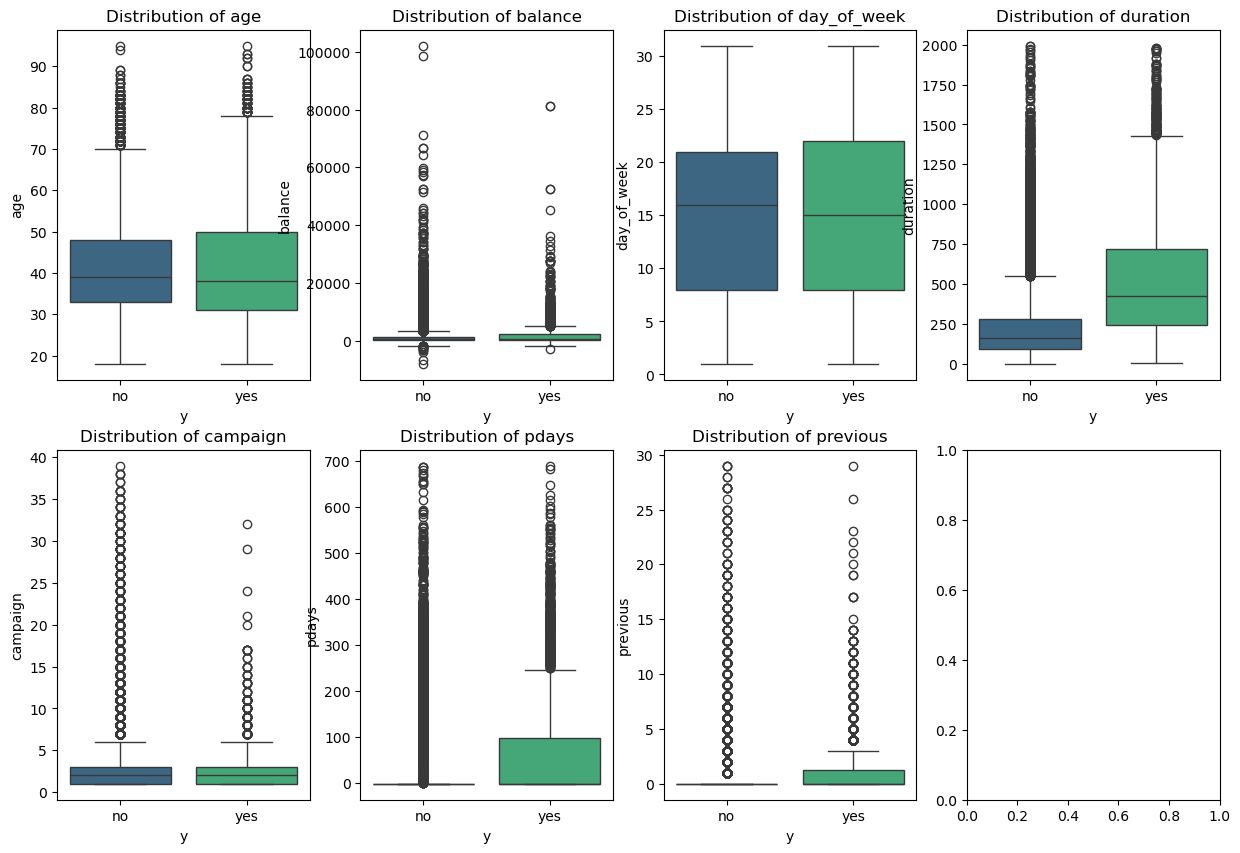

In [153]:
numeric_cols = ['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']
fig, axes = plt.subplots(ncols=4, nrows=2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=col, x='y', data=bank_marketing, ax=axes[i], palette="viridis")
    axes[i].set_title(f'Distribution of {col}')

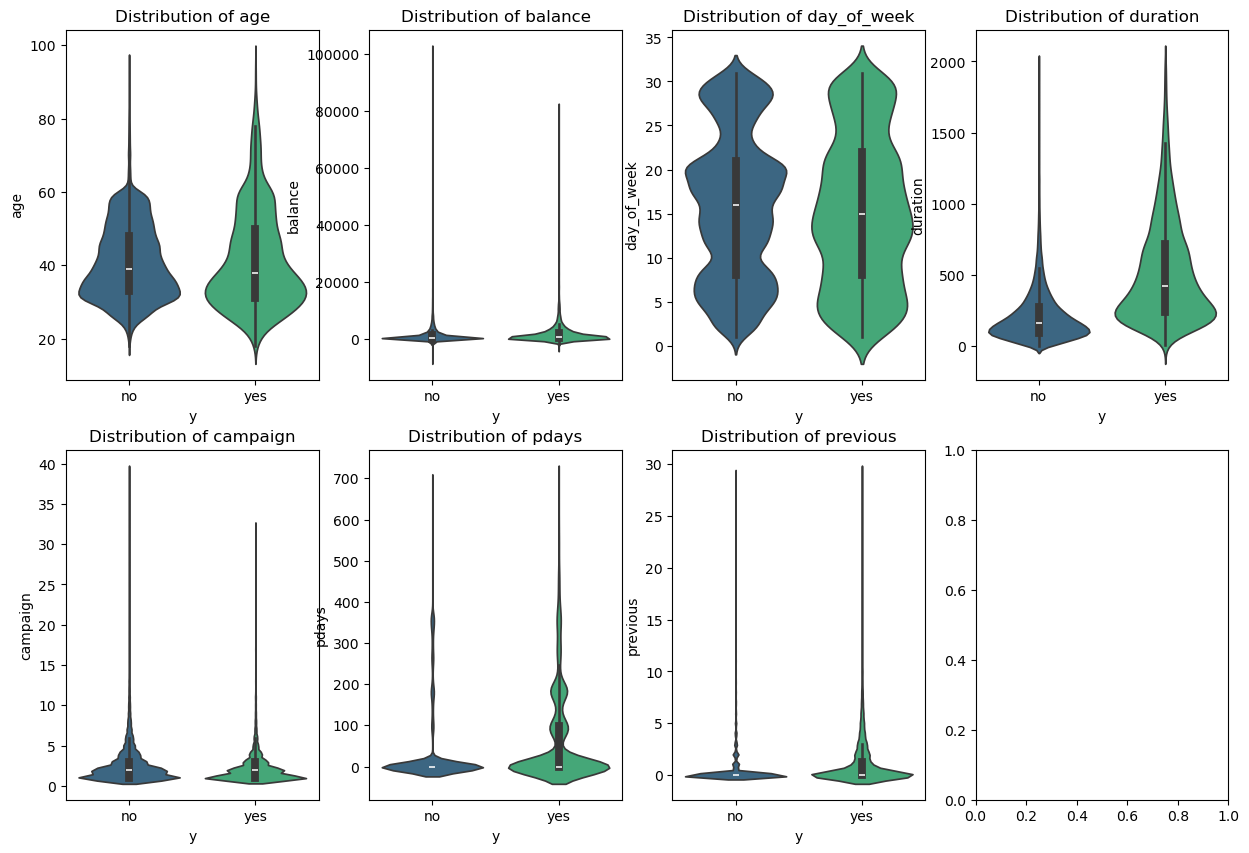

In [154]:
numeric_cols = ['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']
fig, axes = plt.subplots(ncols=4, nrows=2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.violinplot(y=col, x='y', data=bank_marketing, ax=axes[i], palette="viridis")
    axes[i].set_title(f'Distribution of {col}')

In [155]:
bank_marketing.groupby('y')['balance'].median()

y
no     417.0
yes    732.0
Name: balance, dtype: float64

**Observations**
1. More extreme calls (campaign column) are usually related to failed campaigns
2. Distribution of days that passed by after the client was last contacted (pdays) tends to be higher for successful campaigns
3. Distribution of call duration is higher on average for successful campaigns
4. Extreme higher earners are more likely to decline the campaign 

<Axes: >

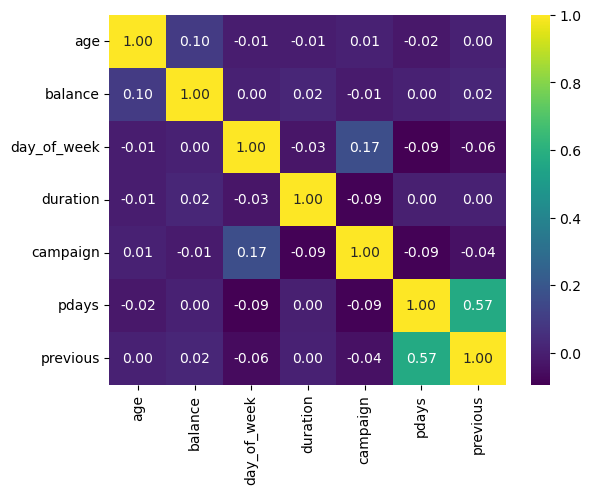

In [156]:
corr =bank_marketing[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='viridis', fmt=".2f")

**Observations**
1. Most of the values are not correllated with each other, however, Previous and pdays are moderately correlated, we can drop pdays

#### Preprocessing and Feature Engineering 

I am going to preprocess the data. Following these steps:
1. Code categorical data into numerical
2. Log transform campaign, balance, and previous
3. Split Data into Test Train Test 
4. Adjust for class imbalance
5. Scale columns

##### Code Categorical Values
I am coding the binary categorical values as 1/0 and the other values as dummy/one-hot encode variables. The month variable will be encoded ordinally. 

In [157]:
bank_marketing[categorical_cols]

,job,marital,education,default,housing,loan,contact,month,poutcome,y
0,management,married,tertiary,no,yes,no,unknown,may,nonexistent,no
1,technician,single,secondary,no,yes,no,unknown,may,nonexistent,no
2,entrepreneur,married,secondary,no,yes,yes,unknown,may,nonexistent,no
3,blue-collar,married,unknown,no,yes,no,unknown,may,nonexistent,no
4,other,single,unknown,no,no,no,unknown,may,nonexistent,no
...,...,...,...,...,...,...,...,...,...,...
45206,technician,married,tertiary,no,no,no,cellular,nov,nonexistent,yes
45207,retired,divorced,primary,no,no,no,cellular,nov,nonexistent,yes
45208,retired,married,secondary,no,no,no,cellular,nov,success,yes
45209,blue-collar,married,secondary,no,no,no,telephone,nov,nonexistent,no


In [158]:
binary_cols = ['default', 'housing', 'loan', 'y']
# binary encoding of categorical columns
label_encoder = LabelEncoder()
for col in binary_cols:
    bank_marketing[col] = label_encoder.fit_transform(bank_marketing[col])

In [160]:
# encode month from 1 to 12
#month_mapping = {'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
               #  'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12}
#bank_marketing['month'] = bank_marketing['month'].map(month_mapping)

In [161]:
#transform categorical columns using one-hot encoding
one_hot_cols = ['job', 'marital', 'education', 'contact', 'poutcome', 'month']

bank_marketing = pd.get_dummies(bank_marketing, columns=one_hot_cols, drop_first=True)

In [162]:
X = bank_marketing.drop(['y', 'pdays'], axis=1)
y = bank_marketing['y']

##### Log Transform Skewed Variables

In [163]:
# Log transformation of skewed features
skewed_features = ['duration', 'campaign', 'previous']
for feature in skewed_features:
   X[feature] = np.log1p(X[feature])  # log1p is used to avoid log(0) issues

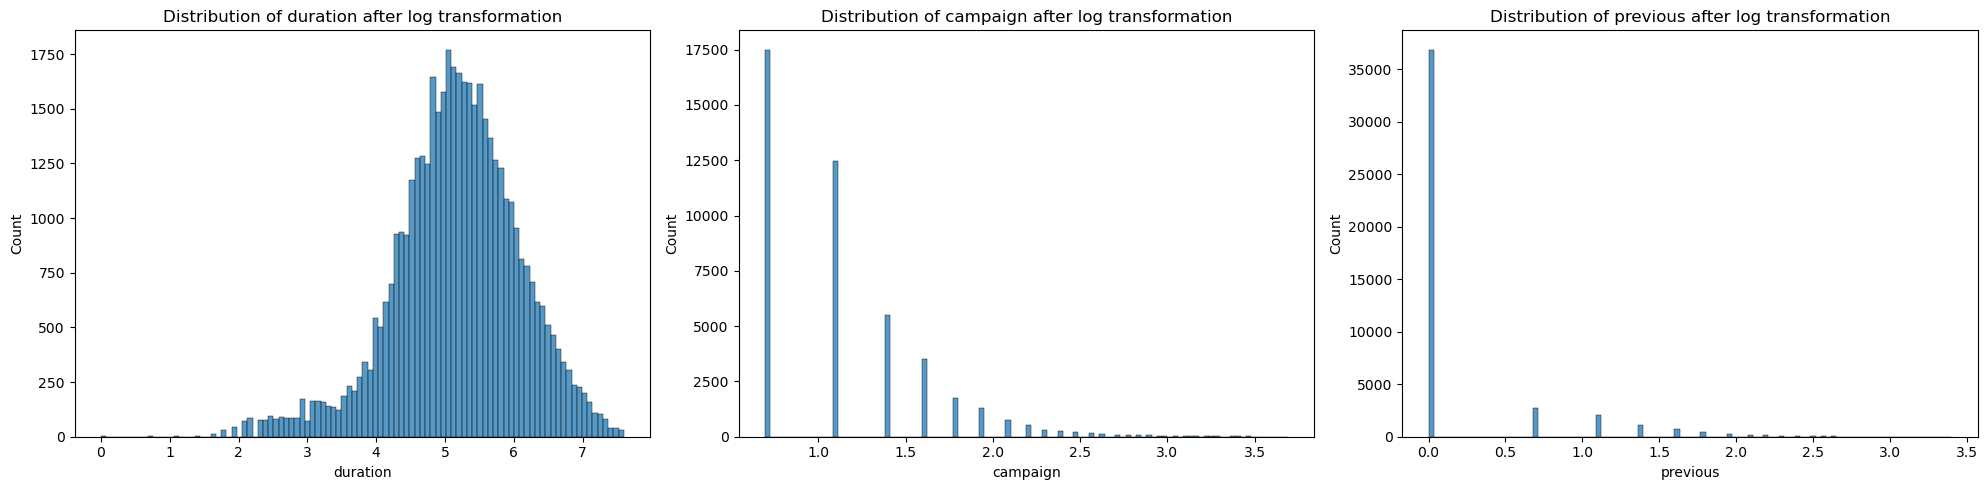

In [164]:
fig, axes = plt.subplots(ncols=3, nrows=1, figsize=(20, 5))
for i, col in enumerate(skewed_features):
    sns.histplot(X[col], bins=100, ax=axes[i])
    axes[i].set_title(f'Distribution of {col} after log transformation')
plt.tight_layout()
plt.show()

##### Split Train Test Split
I would use stratified Train Test Split

In [165]:
# Train test Split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=77, stratify=y)

##### Adjust Class Imbalance
There is an imbalance in the target, this can cause the model to learn to predict the dominant class most of the time and this will lead to high accuracy scores, despite being wrong on less dominant class. Here I will use SMOTE.

<Axes: xlabel='y', ylabel='count'>

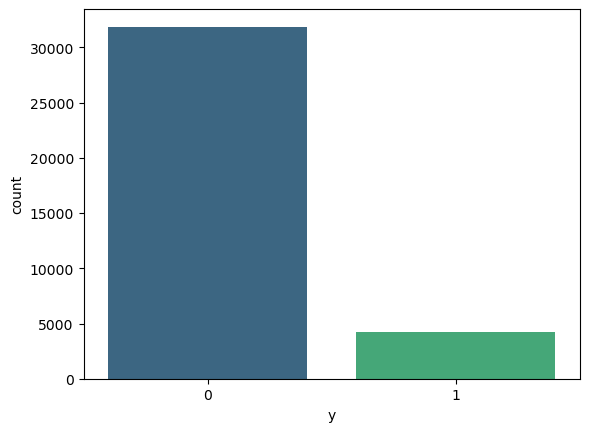

In [166]:
sns.countplot(x=y_train, palette="viridis")

In [167]:
smote = SMOTE(random_state=77)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

<Axes: xlabel='y', ylabel='count'>

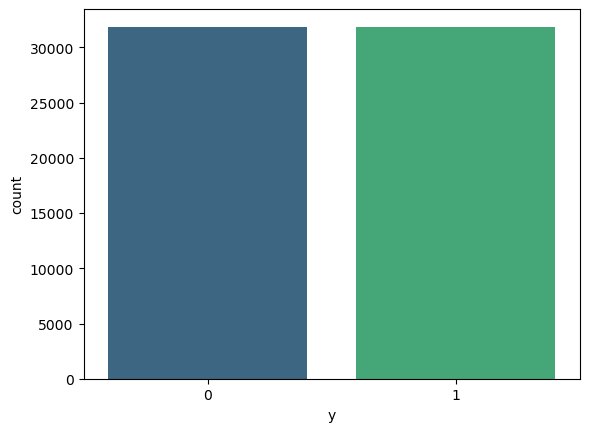

In [168]:
sns.countplot(x=y_train_resampled, palette="viridis")

### Modelling
I will model the data using Logistic Regression, Random Forrest and Gradient Boosted Trees. I want to follow this process:

1. Create Pipeline
2. Create CV using Stratified Cross Validation Score. 
3. Use this method to select the best Hyperparameters using Random Search CV. 
4. Fit with best estimator 

In [169]:
logistic_model = LogisticRegression()

logistic_model.fit(X_train_resampled, y_train_resampled)


LogisticRegression()

In [170]:
y_pred = logistic_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8057434305355361
Precision: 0.3050471436494731
Recall: 0.5243088655862727
F1 Score: 0.3856942496493689


In [201]:
#predict probabilities
threshold = 0.6
probs = logistic_model.predict_proba(X_test)[:, 1]

y_pred = (probs > threshold).astype(int)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8402261891562257
Precision: 0.3554572271386431
Recall: 0.45948522402287895
F1 Score: 0.40083160083160085


<Axes: >

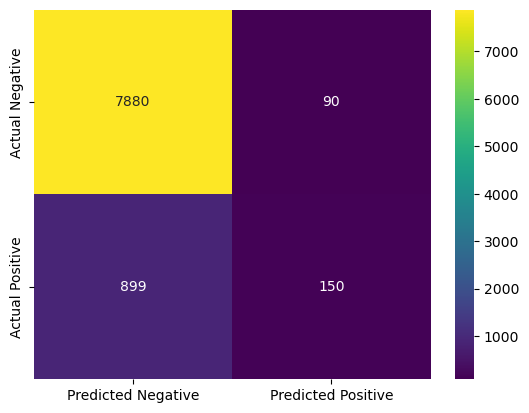

In [173]:
# binary encoding of categorical columns
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_df = pd.DataFrame(conf_matrix, index=['Actual Negative', 'Actual Positive'], columns=['Predicted Negative', 'Predicted Positive'])  
sns.heatmap(conf_matrix_df, annot=True, fmt='d', cmap='viridis')

**Observation from intitial model**
There is high recall and low precision, meaning the model tends to predict actual positives as positives, but it is predicting actual negatives as positives a lot of the times.

In [190]:
random_forest = RandomForestClassifier(random_state=77)


param_grid = {
    'n_estimators': [50],
    'max_depth': [3, 5],
    'min_samples_split': [1000, 1500, 2000],
    'min_samples_leaf': [ 1000, 1500, 2000]
}

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=77)

grid_rf = RandomizedSearchCV(estimator=random_forest, 
                                param_distributions=param_grid, 
                                n_iter=10, 
                                cv=kfold, 
                                scoring='f1', 
                                random_state=77, 
                                n_jobs=-1)

grid_rf.fit(X_train_resampled, y_train_resampled)

print("Best Parameters:", grid_rf.best_params_)
print("Best F1 Score:", grid_rf.best_score_)

Best Parameters: {'n_estimators': 50, 'min_samples_split': 1500, 'min_samples_leaf': 1000, 'max_depth': 5}
Best F1 Score: 0.8807394398964487


In [191]:
grid_rf_best = grid_rf.best_estimator_
y_pred = grid_rf_best.predict(X_test)

In [192]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))  
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8590752855083712
Precision: 0.4262948207171315
Recall: 0.6120114394661582
F1 Score: 0.5025440313111545


**Observations**
Despite the Model doing well on the train-validation set, it does very badly on the test set. This is due to overfitting. 

In [177]:
# Pipeline Creation
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression())
])

In [194]:
# Parameter grid for RandomizedSearchCV
param_grid = [
    {
        'classifier': [LogisticRegression()],
        'classifier__C': [0.01, 0.1, 1, 10, 100]
    },
    {  
        'classifier': [RandomForestClassifier()],
        'classifier__n_estimators': [50, 60, 70, 80],
        'classifier__max_depth': [3, 5, 10],
        'classifier__min_samples_split': [1000, 1500, 2000],
        'classifier__min_samples_leaf': [1000, 1500, 2000]
    },
    {
        'classifier': [GradientBoostingClassifier()],
        'classifier__n_estimators': [50, 60, 70, 80],
        'classifier__learning_rate': np.arange(0.01, 0.5, 0.05),
        'classifier__max_depth': [3, 5, 10],
        'classifier__min_samples_split': [1000, 1500, 2000],
        'classifier__min_samples_leaf': [1000, 1500, 2000]
    }
]

stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=77)

random_search = RandomizedSearchCV(estimator=pipeline, 
                                param_distributions=param_grid, 
                                n_iter=50, 
                                cv=stratified_kfold, 
                                scoring='f1',  
                                random_state=77, 
                                n_jobs=-1)

In [195]:
random_search.fit(X_train_resampled, y_train_resampled)
y_pred = random_search.predict(X_test)

In [196]:
print("best parameters:", random_search.best_params_)
print("best score:", random_search.best_score_)

best parameters: {'classifier__n_estimators': 80, 'classifier__min_samples_split': 1500, 'classifier__min_samples_leaf': 1000, 'classifier__max_depth': 10, 'classifier__learning_rate': np.float64(0.41000000000000003), 'classifier': GradientBoostingClassifier()}
best score: 0.9415165870651727


In [198]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))      
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.9010976826699191
Precision: 0.5863586358635864
Recall: 0.5081029551954243
F1 Score: 0.5444330949948928


Exception ignored in: <function ResourceTracker.__del__ at 0x1135ed8a0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10258d8a0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1024b58a0>
Traceback (most recent call last